# Iris 데이터셋 분석
**목표:** 붓꽃 데이터의 변수 간 관계 분석과 시각화

- 데이터: `sklearn.datasets.load_iris` (150개 샘플, 4개 특성, 3개 품종)
- 구조파악 => 전처리 점검 => 분포 => 변수 간 관계 => 상관관계 => PCA
- 참고: https://wikidocs.net/217157

## 환경 설정

In [1]:
# 한글 폰트 설정 (Colab)
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

# numpy, pandas, matplotlib, sklearn 사용
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 폰트 설정 및 테마 설정
plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)
sns.set_theme(style='whitegrid', font='NanumGothic', rc={'axes.unicode_minus': False})
pd.set_option('display.max_columns', None)

## 1. 데이터 로드

In [7]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True) # data load (sklearn 내장)
df = iris.frame.copy()

df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'target']
# column 이름 정제

print("raw data :")
df_ = df.head()

df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df = df.drop(columns='target')
# 0, 1, 2 => 'setosa', 'versicolor', 'virginica' 매핑
# 숫자 라벨은 보기 어려우니 문자열 라벨로 역매핑 해둠

display(df_.head())
print("\n")
display(df.head())

raw data :


,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. 데이터 구조 파악

In [8]:
print('shape:', df.shape)
df.info()

# column sepal_l,w,  petal_l,w, species
# 수치형은 모두 float64, 범주형(종)은 object

shape: (150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [9]:
df.describe().T
# 평균 수치, 표준편차, 최소값 등의 값 분포 확인 (전치행렬로)
# 전체 150개 데이터에 결측치 없이 채워져 있음 (모든 col값 결측X)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


In [10]:
df['species'].value_counts() # 종별로 50개씩 데이터 존재 (x3종, 총 150개)

,count
species,
setosa,50
versicolor,50
virginica,50


## 3. 결측치, 이상치, 중복값 분석 및 처리

In [11]:
print('결측치:\n', df.isnull().sum())
print('\n중복 행 수:', df.duplicated().sum())
df[df.duplicated(keep=False)]

# 결측치, 중복값 개수 계산후 중복값 확인
# 중복값은 딱 한개(2pair)

결측치:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

중복 행 수: 1


,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


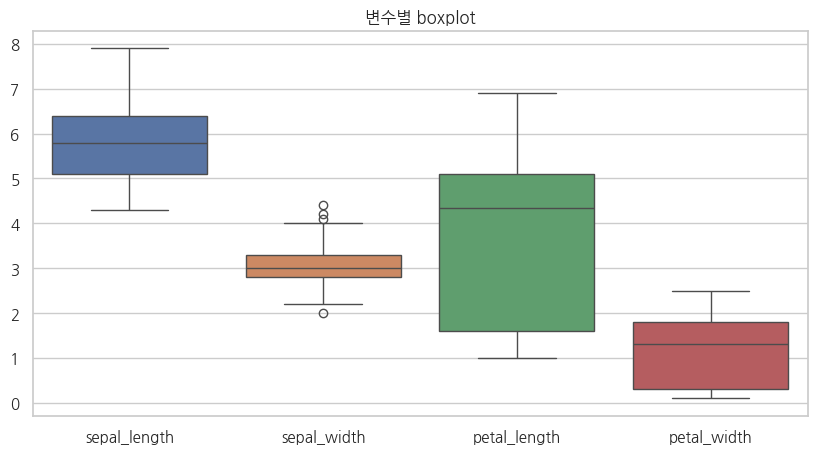

In [13]:
# 중복 행은 실제 측정값이 같을 수 있으므로 확인만 하고 처리 X
# features 에 각 col 담아주기 (순회를 위한 변수)
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[features])
plt.title('변수별 boxplot')
plt.show()

# 변수별 값 분포 시각화 (boxplot)

In [14]:
# IQR 이상치 (ML: IQR = Q_3 - Q_1 통계적 이상치판별지표)
for c in features:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    out = df[(df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)]
    print(f'{c}: {len(out)}개', out[c].tolist())

# col순회하며 Q1-(1.5*IQR)~Q3+(1.5*IQR) 범위 벗어나는 col 개수탐지: width값 4개
# 따로 처리할 필요는 없을 것으로 판단, 그대로 둠

sepal_length: 0개 []
sepal_width: 4개 [4.4, 4.1, 4.2, 2.0]
petal_length: 0개 []
petal_width: 0개 []


## 4. 변수 분포

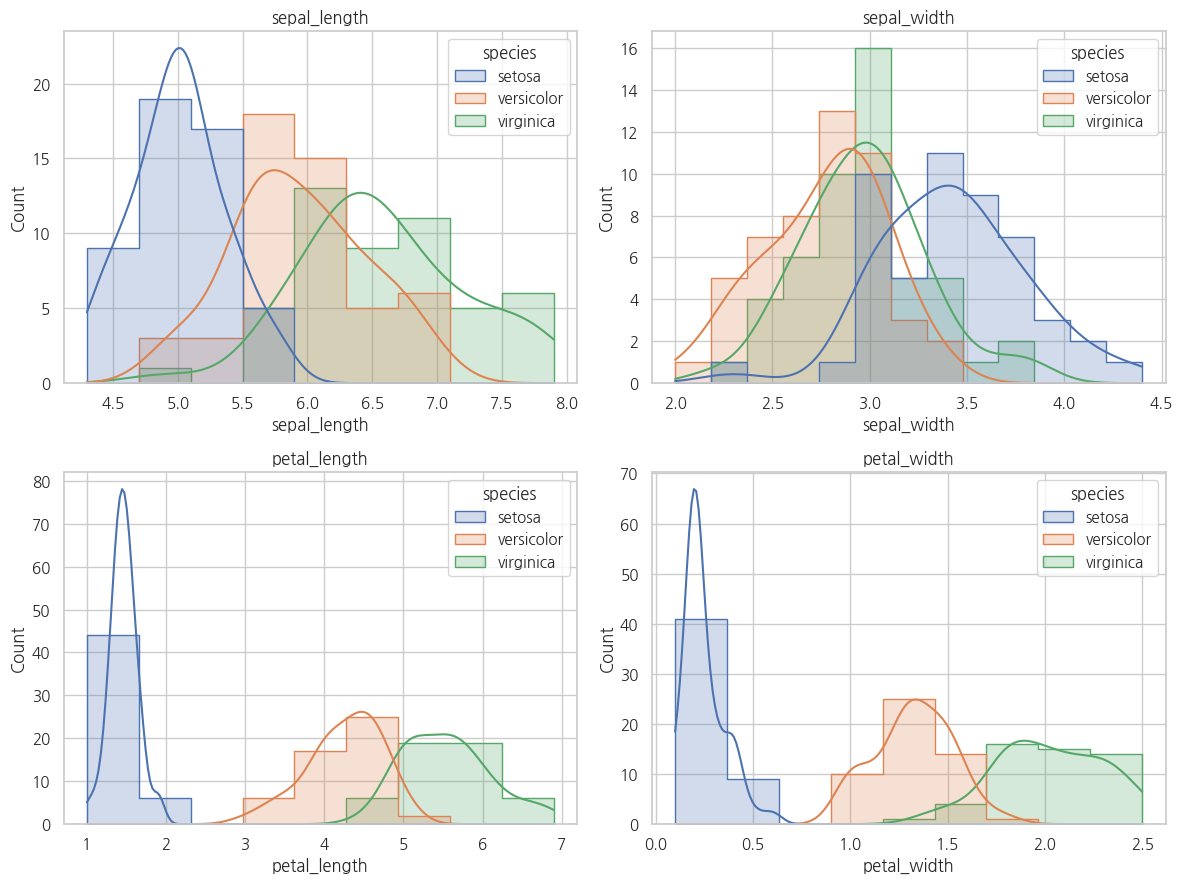

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, col in zip(axes.flat, features):
    sns.histplot(data=df, x=col, hue='species', kde=True, ax=ax, element='step')
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 꽃받침(sepal), 꽃잎(petal)의 너비/높이별 값 분포 histplot
# 가장 분류에 유리해 보이는 성질은 petal_len, width 로 보임 (특성 뚜렷)


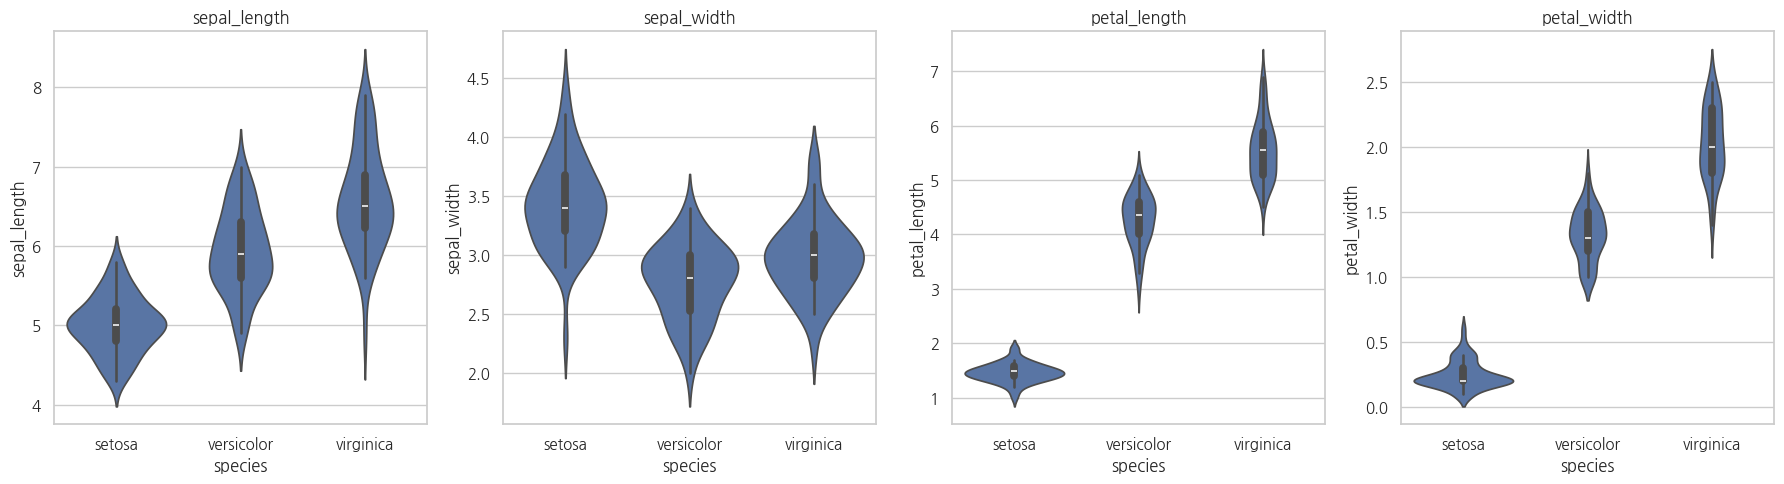

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, col in zip(axes, features):
    sns.violinplot(data=df, x='species', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 각 특성별 violinplot
# 여기서도 petal 의 len, width 가 분류 문제에 좋은 특성임을 알 수 있음
# sepal 은 값이 비교적 비슷한 경향을 가짐

In [17]:
df.groupby('species')[features].agg(['mean', 'std']).round(2)

# 수치형 컬럼들 (위 4개 col=feature) 의 평균 표준편차 계산
# violinplot 과 함께 보아 중심위치, 퍼진 정도(std)를 분석해볼 수 있음
# sepal 값이 petal값에 비해 표준편자값이 더 큰 것을 확인할 수 있음(범위적임)

sepal_length       sepal_width       petal_length        \
                   mean   std        mean   std         mean   std   
species                                                              
setosa             5.01  0.35        3.43  0.38         1.46  0.17   
versicolor         5.94  0.52        2.77  0.31         4.26  0.47   
virginica          6.59  0.64        2.97  0.32         5.55  0.55   

           petal_width        
                  mean   std  
species                       
setosa            0.25  0.11  
versicolor        1.33  0.20  
virginica         2.03  0.27

## 5. 변수 간 관계

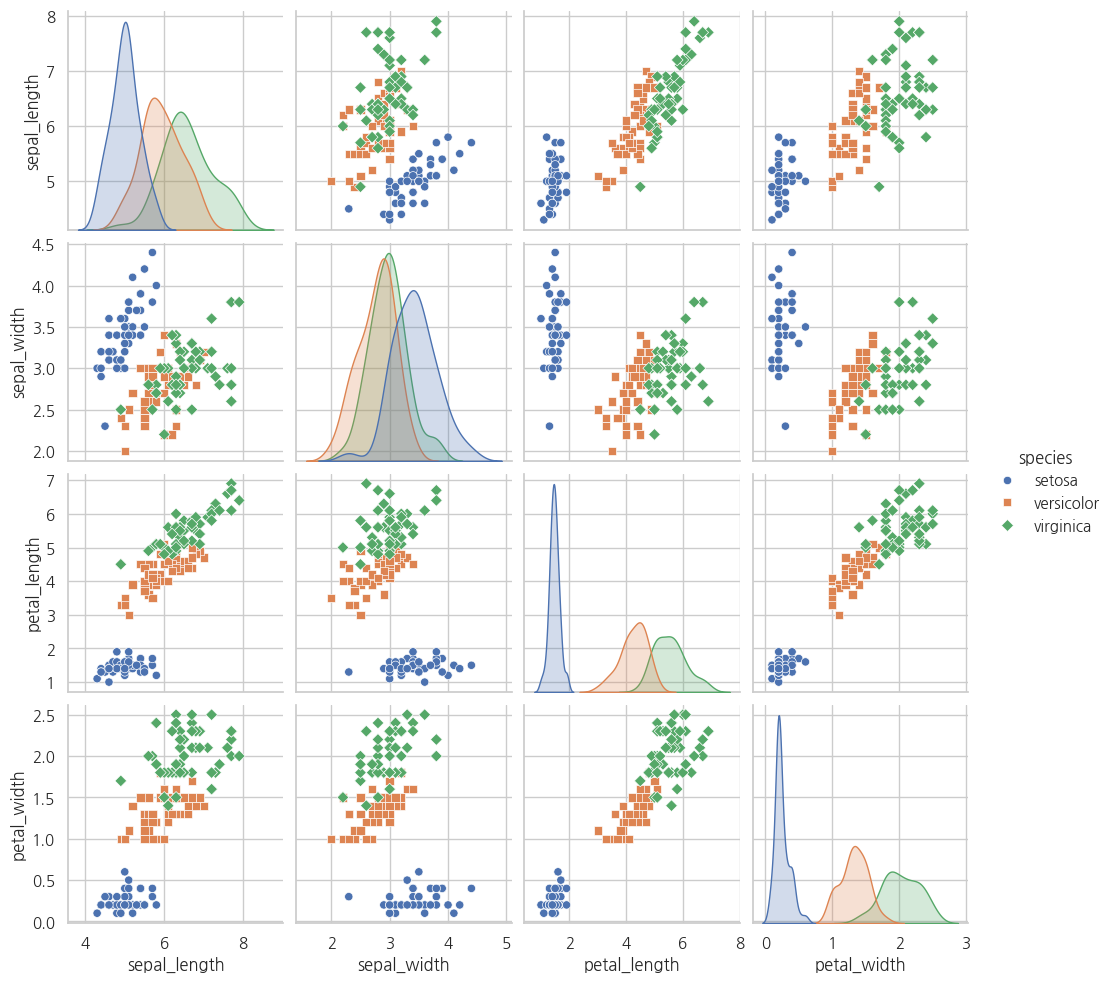

In [18]:
sns.pairplot(df, hue='species', diag_kind='kde', markers=['o', 's', 'D'])
plt.show()

# pairplot (산점도 그래프)
# sepal 끼리의 feature 산점도그래프는 훨씬 겹친 부분이 많은데,
# petal 끼리의 그래프는 특징적인 경향
# sepal feautre값과 함께 보면 petal 값의 특징적인 성질이 잘 보임.

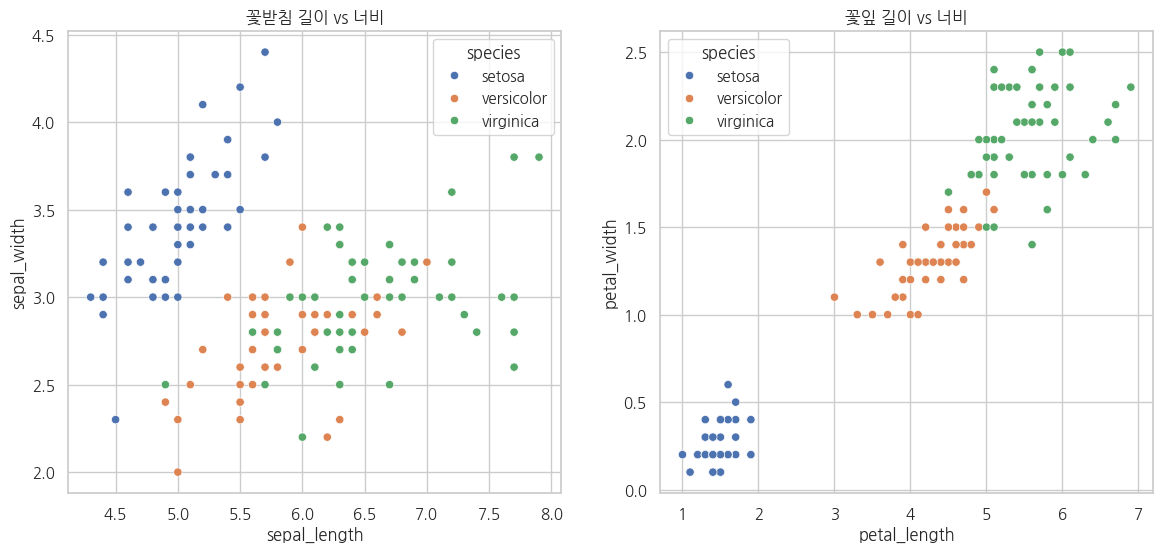

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(data=df, x='sepal_length', y='sepal_width', hue='species', ax=axes[0])
axes[0].set_title('꽃받침 길이 vs 너비')

sns.scatterplot(data=df, x='petal_length', y='petal_width', hue='species', ax=axes[1])
axes[1].set_title('꽃잎 길이 vs 너비')

plt.show()

# scatterplot (산점도) 그래프 :  sepal vs. petal
# 여기서도 꽃받침 feature 값들보다 꽃잎 feature값이 더 경계가 명확한것이 보임

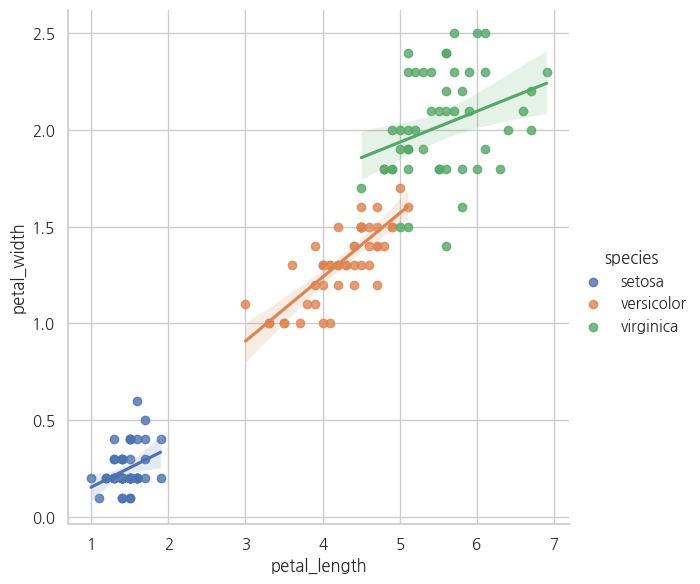

In [20]:
# 회귀선으로 품종별 관계 확인
sns.lmplot(data=df, x='petal_length', y='petal_width', hue='species', height=6)
plt.show()

## 6. 상관관계

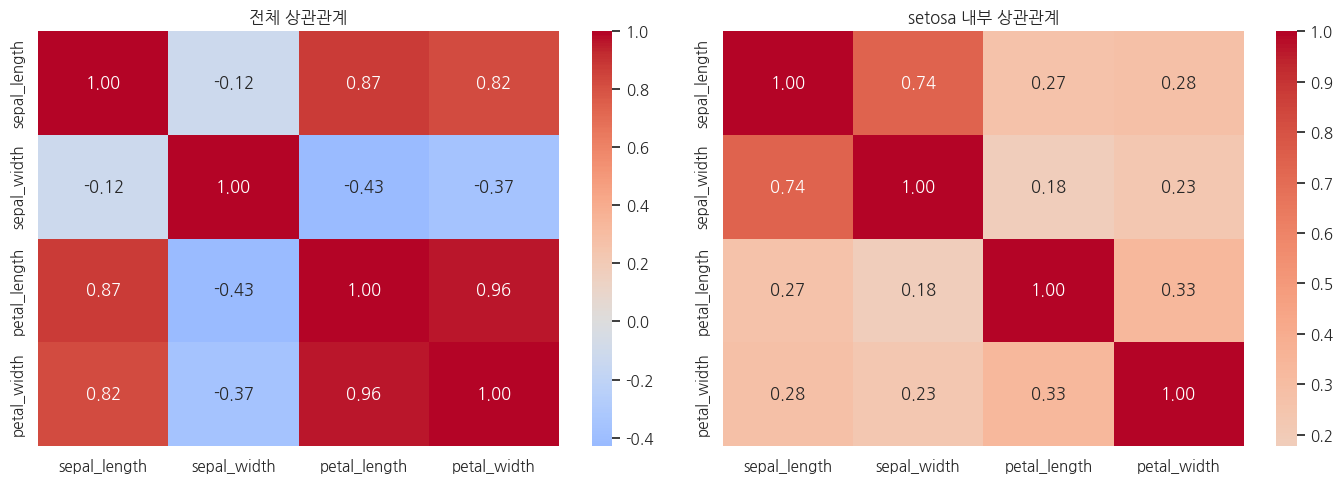

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(df[features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0])
axes[0].set_title('전체 상관관계')

sns.heatmap(df[df.species == 'setosa'][features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('setosa 내부 상관관계')
plt.tight_layout()

plt.show()

# sepal 길이가 길수록 petal 길이와 petal 너비가 긴 경향
# petal 길이와 너비는 매우 큰 상관관계 가졌으며,
# sepal 길이와 너비는 작은 음의 상관관계를 가지는 특이한 관계 가짐

# 여기서 의문점 : sepal 길이와 너비는 작은 음의 상관관계였는데
# 오른쪽 한 품종 내부에서 sepal len,width 끼리 관련도가 높음

> 전체 데이터에서는 `sepal_length`–`sepal_width`가 약한 음의 상관이지만,
품종 내부에서는 양의 상관



=>  **심슨의 역설** 사례

: 데이터를 세부 그룹별로 나누어 분석한 결과와 전체를 합쳐서 분석한 결과의 추세가 반대로 나타나는 통계 현상

=> 그룹을 나눠서 보는 것이 중요하다

(다각도 분석이 필요한 이유, 데이터는 생각보다 고차원적인 경우가 많다)

In [22]:
for sp, g in df.groupby('species'):
    print(sp, '| sepal_length~sepal_width 상관:', round(g['sepal_length'].corr(g['sepal_width']), 2))
print('전체 | ', round(df['sepal_length'].corr(df['sepal_width']), 2))

setosa | sepal_length~sepal_width 상관: 0.74
versicolor | sepal_length~sepal_width 상관: 0.53
virginica | sepal_length~sepal_width 상관: 0.46
전체 |  -0.12


## 7. 파생 변수 & 스케일링 & PCA

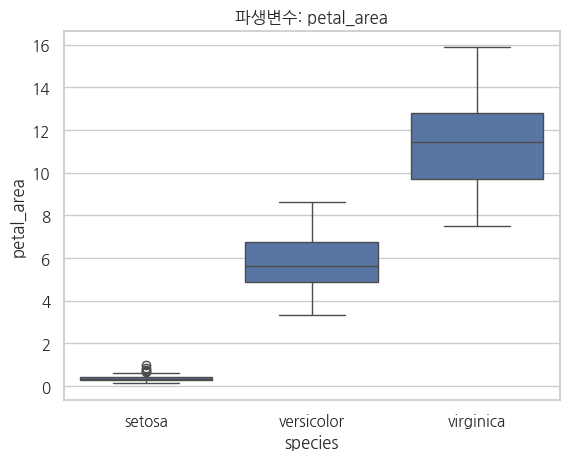

In [23]:
df['petal_area'] = df['petal_length'] * df['petal_width']
df['sepal_area'] = df['sepal_length'] * df['sepal_width']

sns.boxplot(data=df, x='species', y='petal_area')
plt.title('파생변수: petal_area')

plt.show()

# 꽃잎의 면적을 근사한 수치로 품종간 비교
# virginica, versicolor, setosa 순으로 큼
# 특히 setosa의 크기가 눈에 띄게 작음

설명된 분산 비율: [0.73  0.229]


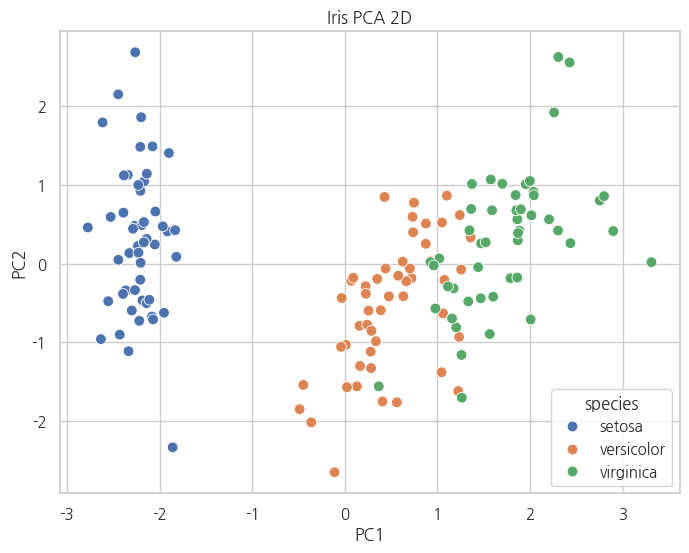

,sepal_length,sepal_width,petal_length,petal_width
PC1,0.521,-0.269,0.580,0.565
PC2,0.377,0.923,0.024,0.067


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(df[features])
pca = PCA(n_components=2)
pc = pca.fit_transform(X)
print('설명된 분산 비율:', pca.explained_variance_ratio_.round(3))
# 정규화(standardscaler) => PCA로 extract => 두 축이 raw에서 얼마만큼설명하나 보여줌)
# 즉, 추출한 특성이 어떤특성에서 나온것인지 대강 보여줌
# 결과를 보아, 첫번째가 70%정도를 설명하고 두번째가 20%정도를 설명하도록 추출된 특성

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pc[:, 0], y=pc[:, 1], hue=df['species'], s=60)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Iris PCA 2D')
plt.show()

pd.DataFrame(pca.components_, columns=features, index=['PC1', 'PC2']).round(3)

# 주성분 분석 (PCA)
# 4개 특성을 2개 특성 (4d=>2d feature) 으로 압축해 본질적 데이터 추출
# PCA를 통해 추출해낸 feature 2가지를 통해 그래프를 그려봄
# 결과를 보면 잘 추출된 것이 보임 (경계선 명확)

# PC1 의 sepal width 에 집중할 필요 있음:
# PC1에서는 음의 상관관계로 반대로 작용하는 수준이지만
# PC2에서는 이를 매우 잘 표현함 (담당을 크게 가져간 느낌)
# 이와 같이 두 주축이된 feature가 기존 feature 특성을 나눠 가져감을 알 수 있음

## 8. 정리
- 결측치 없음, 중복 행 일부 존재(실측값 동일 가능성), `sepal_width`에 소수 이상치
- 꽃잎(`petal_*`) 변수가 품종 구분에 가장 효과적: setosa는 완전히 분리됨
- versicolor와 virginica는 일부 겹침
- `petal_length`–`petal_width` 상관이 매우 높음 (~= 0.96)
- 전체 vs 품종별 상관 방향이 다른 심슨의 역설 관찰

&nbsp;&nbsp;&nbsp;&nbsp; <img src="https://lrl.kr/gputa" width="400" height="190">